
# Pitch Basics

First we import the Pitch classes and matplotlib


In [1]:
!pip install mplsoccer pandas-summary

import matplotlib.pyplot as plt

from mplsoccer import Pitch, VerticalPitch

plt.rcdefaults() # cancel the xqcd

## Draw a pitch on a new axis
Let's plot on a new axis first.



In [2]:
# import csv

# # Define the path to your CSV file
# csv_file_path = 'Session-Mateo-gps.csv'

# # Initialize an empty list to store the data
# sheet = []

# # Open and read the CSV file
# with open(csv_file_path, 'r') as file:
#     csv_reader = csv.reader(file)
#     header = next(csv_reader)  # Read the header row (if it exists)
#     sheet.append(header)  # Add the header to the data list (optional)
    
#     for row in csv_reader:
#         sheet.append(row)

# # Display the data
# for row in sheet[:10]:
#     print(row)

In [3]:
import pandas as pd
# csv_file_path = 'Session-28-10-2023-trimmed.csv'
# csv_file_path = 'Session_28-10-2023.csv'
csv_file_path = 'Albion_BIEN_25-5-2024.csv'

df = pd.read_csv(csv_file_path)
# df.columns = ['Player Display Name', 'Time', 'Elapsed Time (s)', 'Lat', 'Lon', 'Speed km/h', 'Instantaneous Acceleration Impulse', 'Heart Rate (bpm)', 'basura']
# df.columns = df.columns.str.strip()
df['Speed km/h'] = df['Speed (m/s)'] *3.6

#https://www.google.com/maps/place/34%C2%B047'45.4%22S+56%C2%B008'51.9%22W/@-34.7954353,-56.1481298,189m/data=!3m1!1e3!4m4!3m3!8m2!3d-34.7959307!4d-56.1477602?entry=ttu
# -34.794926, -56.148368
# -34.795816, -56.147428

lat_lower_bound = -34.795816
lat_upper_bound = -34.794926
lon_lower_bound = -56.148368
lon_upper_bound = -56.147428
fix_df = df[(df['Lat'] > lat_lower_bound) & (df['Lat'] < lat_upper_bound)]
fix_df = fix_df[(fix_df['Lon'] > lon_lower_bound) & (fix_df['Lon'] < lon_upper_bound)]

In [4]:
fix_df

,Player Id,Player Display Name,Time,Elapsed Time (s),Lat,Lon,Speed (m/s),Instantaneous Acceleration Impulse,Heart Rate (bpm),Speed km/h
0,68,Del Pino Esquivo,09:03:56.02,0.019998,-34.795304,-56.147873,1.138890,0.750001,NaN,4.100003
1,68,Del Pino Esquivo,09:03:56.03,0.029998,-34.795304,-56.147873,1.138890,0.750001,NaN,4.100003
2,68,Del Pino Esquivo,09:03:56.04,0.039998,-34.795304,-56.147873,1.138890,0.750001,NaN,4.100003
3,68,Del Pino Esquivo,09:03:56.05,0.049998,-34.795304,-56.147873,1.138890,0.750001,NaN,4.100003
4,68,Del Pino Esquivo,09:03:56.06,0.059998,-34.795304,-56.147873,1.138890,0.750001,NaN,4.100003
...,...,...,...,...,...,...,...,...,...,...
999994,82,Calione Fuentes,09:47:05.06,2599.069212,-34.795410,-56.148044,1.175001,0.666667,NaN,4.230003
999995,82,Calione Fuentes,09:47:05.07,2599.079212,-34.795410,-56.148044,1.175001,0.666667,NaN,4.230003
999996,82,Calione Fuentes,09:47:05.08,2599.089212,-34.795410,-56.148044,1.175001,0.666667,NaN,4.230003
999997,82,Calione Fuentes,09:47:05.09,2599.099212,-34.795410,-56.148044,1.175001,0.666667,NaN,4.230003



# Analisis Descriptivo


In [5]:
summary_lon = fix_df['Lon'].describe()
summary_lat = fix_df['Lat'].describe()

print("summary_lon:\n", summary_lon)
print("summary_lat:\n", summary_lat)

summary_lon:
 count    881886.000000
mean        -56.147859
std           0.000247
min         -56.148316
25%         -56.148070
50%         -56.147901
75%         -56.147623
max         -56.147428
Name: Lon, dtype: float64
summary_lat:
 count    881886.000000
mean        -34.795308
std           0.000208
min         -34.795816
25%         -34.795434
50%         -34.795279
75%         -34.795150
max         -34.794926
Name: Lat, dtype: float64


In [6]:
from pandas_summary import DataFrameSummary

# Get a summary of the DataFrame

numeric_columns = fix_df.select_dtypes(include=['number'])

summary = DataFrameSummary(numeric_columns)

# Print the summary
print(summary.summary())

             Player Id Elapsed Time (s)        Lat        Lon Speed (m/s)  \
count         881886.0         881886.0   881886.0   881886.0    881886.0   
mean          72.10942      2840.353153 -34.795308 -56.147859    1.603966   
std           6.375311      2070.378714   0.000208   0.000247    1.426637   
min               68.0         0.019998 -34.795816 -56.148316         0.0   
25%               68.0      1116.830756 -34.795434  -56.14807       0.575   
50%               68.0      2219.512755 -34.795279 -56.147901    1.258334   
75%               82.0      4698.983945  -34.79515 -56.147623    2.411113   
max               82.0       6955.84637 -34.794926 -56.147428    9.327785   
counts          881886           881886     881886     881886      881886   
uniques              2           881886       5292       5272        2560   
missing              0                0          0          0           0   
missing_perc        0%               0%         0%         0%          0%   

In [7]:
# Get the minimum and maximum values for 'Column1'
min_value_lat = fix_df['Lat'].min()
max_value_lat = fix_df['Lat'].max()

# Get the minimum and maximum values for 'Column2'
min_value_lon = fix_df['Lon'].min()
max_value_lon = fix_df['Lon'].max()

print(f"Minimum of player min_value_lat: {min_value_lat}")
print(f"Maximum of player max_value_lat: {max_value_lat}")
print(f"Minimum of player min_value_lon: {min_value_lon}")
print(f"Maximum of player max_value_lon: {max_value_lon}")

Minimum of player min_value_lat: -34.7958155
Maximum of player max_value_lat: -34.79492617
Minimum of player min_value_lon: -56.14831633
Maximum of player max_value_lon: -56.14742817


In [8]:
# puntos en cancha
# https://www.google.com/maps/place/34%C2%B047'45.4%22S+56%C2%B008'51.9%22W/@-34.7954353,-56.1481298,189m/data=!3m1!1e3!4m4!3m3!8m2!3d-34.7959307!4d-56.1477602?entry=ttu

# -34.794926, -56.148368
# -34.795816, -56.147428

# Coordenadas de Los cespedes
lat_min = -34.795816
lat_max = -34.794926
lon_min = -56.148368
lon_max = -56.147428


# Trigonometria


In [9]:
# import numpy as np

# # Define the GPS coordinates of four points (A, B, C, D) on the field
# point_A = (-34.794927, -56.148375)
# point_B = (-34.794853, -56.147571)
# point_C = (-34.795902, -56.148234)
# point_D = (-34.795815, -56.147426)

# # Calculate the length and width of the rectangle
# length = np.sqrt((point_A[0] - point_B[0])**2 + (point_A[1] - point_B[1])**2)
# width = np.sqrt((point_A[0] - point_C[0])**2 + (point_A[1] - point_C[1])**2)

# # Determine which sides are length and width
# if length > width:
#     length, width = width, length  # Swap if necessary

# # Calculate the angle between the length side and the North direction
# rotation_angle_radians = np.arctan2(point_B[1] - point_A[1], point_B[0] - point_A[0])
# rotation_angle_degrees = np.degrees(rotation_angle_radians)

# # Ensure the angle is positive (between 0 and 360 degrees)
# if rotation_angle_degrees < 0:
#     rotation_angle_degrees += 360

# print(f"Rotation Angle: {rotation_angle_degrees} degrees")


# Normalizacion de las coordenadas para el Pitch


In [10]:
import pandas as pd
import numpy as np

# Define the rotation angle in degrees
rotation_angle_degrees = 90 + (90 - 84.74132377744776) / 2 # Degrees rotated from North to West

# Convert the rotation angle to radians
rotation_angle_radians = np.radians(rotation_angle_degrees)

# Define the size of the soccer field in meters
# soccer_field_length = 68.81  # In meters
# soccer_field_width = 104.55  # In meters

soccer_field_length = 80  # In meters
soccer_field_width = 120  # In meters


# Function to apply the rotation to coordinates
def rotate_coordinates(row):
    lat, lon = row['Lat'], row['Lon']
    new_lat = lat * np.cos(rotation_angle_radians) - lon * np.sin(rotation_angle_radians)
    new_lon = lat * np.sin(rotation_angle_radians) + lon * np.cos(rotation_angle_radians)
    return pd.Series({'Lat': new_lat, 'Lon': new_lon})


df = fix_df
# Apply the rotation to the coordinates
df[['Lat', 'Lon']] = df.apply(rotate_coordinates, axis=1)

# Scale and normalize the coordinates to the soccer field dimensions
df['Lat_normalized'] = soccer_field_length - (df['Lat'] - df['Lat'].min()) / (df['Lat'].max() - df['Lat'].min()) * soccer_field_length
df['Lon_normalized'] = (df['Lon'] - df['Lon'].min()) / (df['Lon'].max() - df['Lon'].min()) * soccer_field_width


# Display the DataFrame with normalized coordinates
df.head()


,Player Id,Player Display Name,Time,Elapsed Time (s),Lat,Lon,Speed (m/s),Instantaneous Acceleration Impulse,Heart Rate (bpm),Speed km/h,Lat_normalized,Lon_normalized
0,68,Del Pino Esquivo,09:03:56.02,0.019998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986
1,68,Del Pino Esquivo,09:03:56.03,0.029998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986
2,68,Del Pino Esquivo,09:03:56.04,0.039998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986
3,68,Del Pino Esquivo,09:03:56.05,0.049998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986
4,68,Del Pino Esquivo,09:03:56.06,0.059998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986


In [11]:
df_backed_up = df.copy()


# Visualizacion

### Partido completo, segmentado cada 100


881886


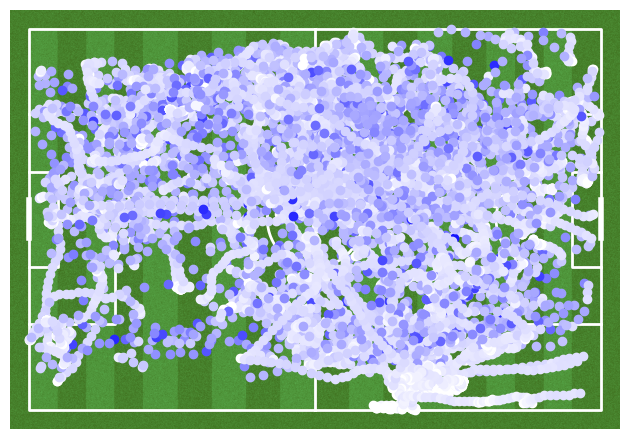

In [12]:
from mplsoccer import Pitch, VerticalPitch

pitch = Pitch(pitch_color='grass', line_color='white',
              stripe=True)  # optional stripes
fig, ax = pitch.draw()


print(len(df))

# cancha: 120x80

step = 100
colors = np.linspace(0, 1, len(df))
# Iterar avanzando de 10 en 10 elementos
for i in range(0, len(df), step):
    # color = (1, 1 - colors[i], 1 - colors[i])
    for index, row in df.iloc[i:i+1].iterrows():
        # print(row['Lat_normalized'],row['Lon_normalized'])
        speed = row['Speed km/h']
        normalized_speed = (speed - df['Speed km/h'].min()) / (df['Speed km/h'].max() - df['Speed km/h'].min())
        color = (1 - normalized_speed, 1 - normalized_speed, 1)  # Gradual transition from white to blue
        ax.scatter(row['Lon_normalized'], row['Lat_normalized'], c=color)


### Primeros minutos

In [13]:
df.iloc[0]

Player Id                                           68
Player Display Name                   Del Pino Esquivo
Time                                       09:03:56.02
Elapsed Time (s)                              0.019998
Lat                                          57.684978
Lon                                         -32.182916
Speed (m/s)                                    1.13889
Instantaneous Acceleration Impulse            0.750001
Heart Rate (bpm)                                   NaN
Speed km/h                                    4.100003
Lat_normalized                               39.360262
Lon_normalized                                67.83986
Name: 0, dtype: object

In [14]:
df.iloc[1]

Player Id                                           68
Player Display Name                   Del Pino Esquivo
Time                                       09:03:56.03
Elapsed Time (s)                              0.029998
Lat                                          57.684978
Lon                                         -32.182916
Speed (m/s)                                    1.13889
Instantaneous Acceleration Impulse            0.750001
Heart Rate (bpm)                                   NaN
Speed km/h                                    4.100003
Lat_normalized                               39.360262
Lon_normalized                                67.83986
Name: 1, dtype: object

In [15]:
# import pandas as pd

# def encontrar_intervalos_coexistencia(df):
#     # Agrupar por tiempo y obtener la lista de jugadores en cada grupo
#     grupos = df.groupby('Elapsed Time (s)')['Player Display Name'].apply(list)
    
#     # Encontrar los intervalos donde todos los jugadores están presentes
#     intervalos_coexistencia = [intervalo for intervalo, jugadores in grupos.items() if set(df['Player Display Name'].unique()) == set(jugadores)]
    
#     return intervalos_coexistencia

# intervalos_coexistencia = encontrar_intervalos_coexistencia(df)
# print("Intervalos de coexistencia:", intervalos_coexistencia)
# df = df_backed_up
display(df)
grupos = df.groupby('Elapsed Time (s)')['Player Display Name'].apply(list)

,Player Id,Player Display Name,Time,Elapsed Time (s),Lat,Lon,Speed (m/s),Instantaneous Acceleration Impulse,Heart Rate (bpm),Speed km/h,Lat_normalized,Lon_normalized
0,68,Del Pino Esquivo,09:03:56.02,0.019998,57.684978,-32.182916,1.138890,0.750001,NaN,4.100003,39.360262,67.839860
1,68,Del Pino Esquivo,09:03:56.03,0.029998,57.684978,-32.182916,1.138890,0.750001,NaN,4.100003,39.360262,67.839860
2,68,Del Pino Esquivo,09:03:56.04,0.039998,57.684978,-32.182916,1.138890,0.750001,NaN,4.100003,39.360262,67.839860
3,68,Del Pino Esquivo,09:03:56.05,0.049998,57.684978,-32.182916,1.138890,0.750001,NaN,4.100003,39.360262,67.839860
4,68,Del Pino Esquivo,09:03:56.06,0.059998,57.684978,-32.182916,1.138890,0.750001,NaN,4.100003,39.360262,67.839860
...,...,...,...,...,...,...,...,...,...,...,...,...
999994,82,Calione Fuentes,09:47:05.06,2599.069212,57.685154,-32.183014,1.175001,0.666667,NaN,4.230003,23.465080,54.679341
999995,82,Calione Fuentes,09:47:05.07,2599.079212,57.685154,-32.183014,1.175001,0.666667,NaN,4.230003,23.465080,54.679341
999996,82,Calione Fuentes,09:47:05.08,2599.089212,57.685154,-32.183014,1.175001,0.666667,NaN,4.230003,23.465080,54.679341
999997,82,Calione Fuentes,09:47:05.09,2599.099212,57.685154,-32.183014,1.175001,0.666667,NaN,4.230003,23.465080,54.679341


In [16]:
cant_intervalos_track = 0
cant_not_track = 0
should_print = False;
for intervalo, jugadores in grupos.items():
    if len(jugadores) > 8:
        cant_intervalos_track += 1
        if should_print:
            print(intervalo, jugadores)
    else:
        cant_not_track +=1 

print(cant_intervalos_track)
print(cant_not_track)

0
881886


# Visualizacion por minuto de juego

elapsed_time 0.0199977541342378 segundo 540.0199977541342 window 60 time_min None time_max None
       Player Id Player Display Name         Time  Elapsed Time (s)  \
54010         68    Del Pino Esquivo  09:12:56.02        540.027561   
54011         68    Del Pino Esquivo  09:12:56.03        540.037561   
54012         68    Del Pino Esquivo  09:12:56.04        540.047561   
54013         68    Del Pino Esquivo  09:12:56.05        540.057561   
54014         68    Del Pino Esquivo  09:12:56.06        540.067561   
...          ...                 ...          ...               ...   
60005         68    Del Pino Esquivo  09:13:55.97        599.976481   
60006         68    Del Pino Esquivo  09:13:55.98        599.986481   
60007         68    Del Pino Esquivo  09:13:55.99        599.996482   
60008         68    Del Pino Esquivo  09:13:56.00        600.006481   
60009         68    Del Pino Esquivo  09:13:56.01        600.016481   

             Lat        Lon  Speed (m/s)  Instantan

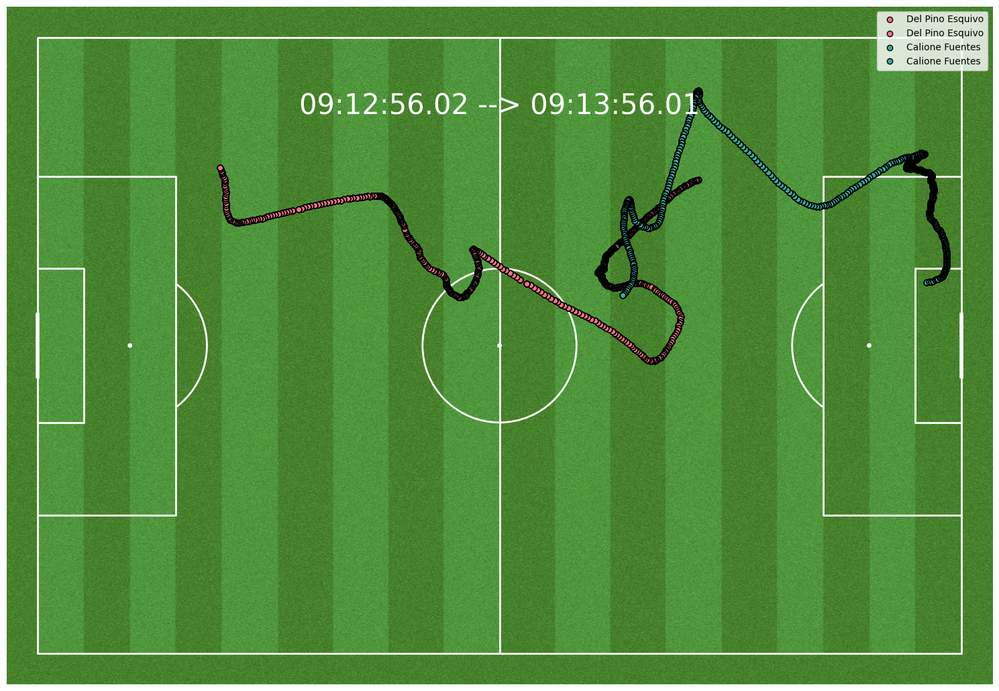

In [17]:
from matplotlib import animation
from matplotlib import pyplot as plt
import seaborn as sns


# https://mplsoccer.readthedocs.io/en/latest/gallery/pitch_plots/plot_animation.html

# First set up the figure, the axis
pitch = Pitch(pitch_color='grass', line_color='white',
              stripe=True)  # optional stripes
fig, ax = pitch.draw(figsize=(16, 10.4))

# then setup the pitch plot markers we want to animate
marker_kwargs = {'marker': 'o', 'markeredgecolor': 'black', 'linestyle': 'None'}
paleta_colores = sns.color_palette("husl", n_colors=len(df['Player Display Name'].unique()))

# Crear un diccionario que asocie cada jugador con un color de la paleta
colores = dict(zip(df['Player Display Name'].unique(), paleta_colores))


# print(colores)

# animation function
def animate(i):
    """ Function to animate the data. Each frame it sets the data for the players and the ball."""
    # set the ball data with the x and y positions for the ith frame
    # get the frame id for the ith frame
    return ax.plot(player_df[['Lon_normalized']], player_df[['Lat_normalized']], ms=6, label=player, markerfacecolor=colores[player], zorder=1, **marker_kwargs)

elapsed_time = min(df['Elapsed Time (s)'])
segundo = elapsed_time+(60*9)
window = 60
time_min = None
time_max = None

print("elapsed_time", elapsed_time, "segundo", segundo, "window", window, "time_min", time_min, "time_max", time_max)

# call the animator, animate so 25 frames per second
for player in df['Player Display Name'].unique():
    player_df = df[(df['Player Display Name'] == player) & (df['Elapsed Time (s)'] > segundo) & (df['Elapsed Time (s)'] < segundo + window)]
    if time_min is None and len(player_df["Time"]):
        print(player_df, len(player_df["Time"]))
        time_min = min(player_df["Time"])
        time_max = max(player_df["Time"]) 
    animation.FuncAnimation(fig, animate, blit=True)
    ax.legend()

annotation = ax.annotate(f'{time_min} --> {time_max}', (60, 10), fontsize=30, ha='center', color="white")

plt.show()

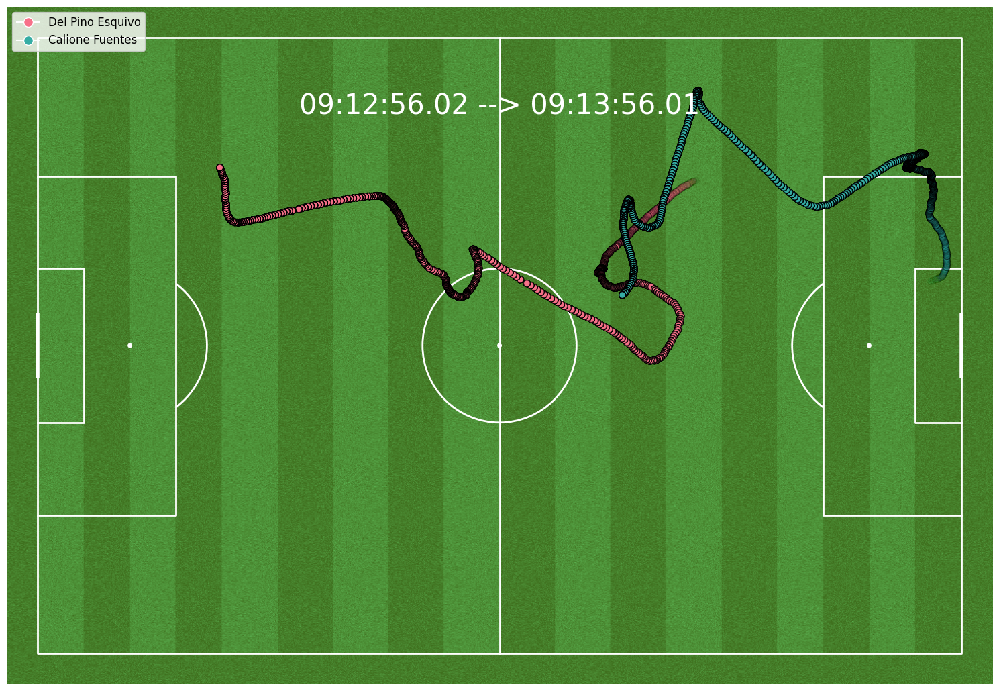

In [18]:
from matplotlib import pyplot as plt
import seaborn as sns
from mplsoccer import Pitch
from matplotlib.lines import Line2D

MUNUTO_DE_JUEGO = 68

segundo_tiempo = MUNUTO_DE_JUEGO > 45
minuto_real_de_juego = MUNUTO_DE_JUEGO - 45 if segundo_tiempo else MUNUTO_DE_JUEGO

# Configuración inicial del campo
pitch = Pitch(pitch_color='grass', line_color='white', stripe=True)
fig, ax = pitch.draw(figsize=(16, 10.4))

# Configuración de la paleta de colores para los jugadores
paleta_colores = sns.color_palette("husl", n_colors=len(df['Player Display Name'].unique()))
colores = dict(zip(df['Player Display Name'].unique(), paleta_colores))

# comienzo_segundo_tiempo

# Filtrar datos para la ventana de tiempo
elapsed_time = min(df['Elapsed Time (s)'])
segundo = elapsed_time + (60 * 9)
window = 60
df_window = df[(df['Elapsed Time (s)'] > segundo) & (df['Elapsed Time (s)'] < segundo + window)]

# Preparar el diccionario con los datos de cada jugador
player_data = {
    player: df_window[df_window['Player Display Name'] == player].reset_index(drop=True)
    for player in df_window['Player Display Name'].unique()
}

# Graficar los puntos de cada jugador
for player, data in player_data.items():
    # Obtener las coordenadas normalizadas de latitud y longitud
    lon_values = data['Lon_normalized']
    lat_values = data['Lat_normalized']
    
    # Calcular la opacidad con base en el índice de los datos (opacidad proporcional)
    opacidad = [i / len(data) for i in range(len(data))]
    
    # Graficar los puntos para el jugador con su color y opacidad
    ax.scatter(
        lon_values, lat_values, 
        color=colores[player], alpha=opacidad, 
        label=player, edgecolor='black', s=50, marker='o'
    )

# Crear leyenda personalizada con los colores de los jugadores
handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=colores[player], markersize=10, label=player)
           for player in df['Player Display Name'].unique()]

# Añadir la leyenda con los colores
ax.legend(handles=handles, loc='upper left', fontsize=12)

annotation = ax.annotate(f'{time_min} --> {time_max}', (60, 10), fontsize=30, ha='center', color="white")

# Mostrar el gráfico
plt.show()


In [19]:
fix_df.head()

,Player Id,Player Display Name,Time,Elapsed Time (s),Lat,Lon,Speed (m/s),Instantaneous Acceleration Impulse,Heart Rate (bpm),Speed km/h,Lat_normalized,Lon_normalized
0,68,Del Pino Esquivo,09:03:56.02,0.019998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986
1,68,Del Pino Esquivo,09:03:56.03,0.029998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986
2,68,Del Pino Esquivo,09:03:56.04,0.039998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986
3,68,Del Pino Esquivo,09:03:56.05,0.049998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986
4,68,Del Pino Esquivo,09:03:56.06,0.059998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986


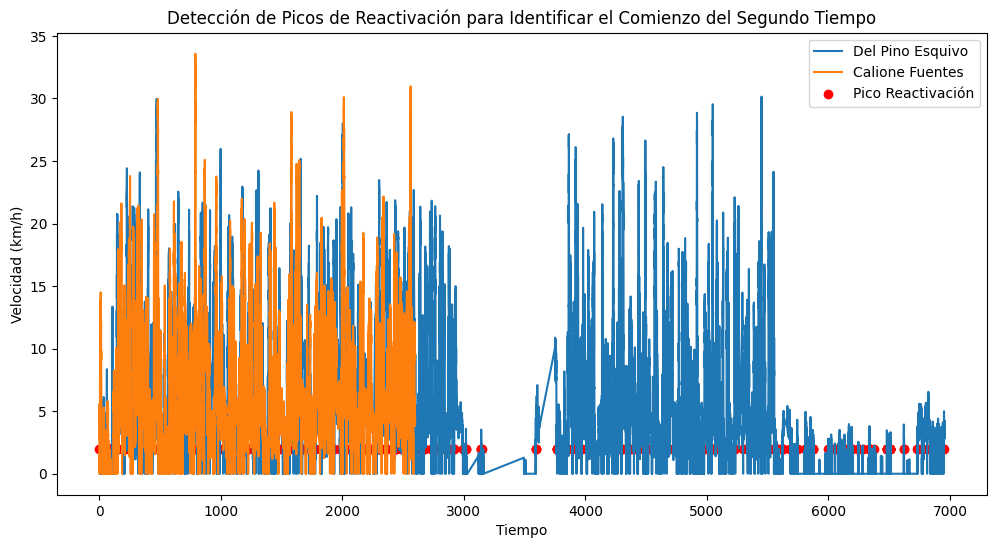

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = df_backed_up

# Filtrar las columnas relevantes
# df['Elapsed Time (s)'] = pd.to_datetime(df['Elapsed Time (s)'])

# Definir un umbral para detectar la reactivación (puedes ajustar este valor)
umbral_velocidad = 2  # velocidad en km/h que consideramos como "alta" para la reactivación

# Calcular las velocidades promedio para cada jugador por el tiempo
df['avg_speed'] = df.groupby('Player Display Name')['Speed km/h'].transform('mean')

# Definir una ventana de tiempo (en segundos) para detectar el pico de reactivación
ventana_tiempo = 15  # puedes ajustar este valor según el intervalo del pico

# Detectar picos de reactivación en las velocidades
reactivacion_indices = []
for player in df['Player Display Name'].unique():
    player_data = df[df['Player Display Name'] == player]
    for i in range(ventana_tiempo, len(player_data)):
        if player_data['Speed km/h'].iloc[i] > umbral_velocidad and all(player_data['Speed km/h'].iloc[i-ventana_tiempo:i] < umbral_velocidad):
            reactivacion_indices.append(player_data['Elapsed Time (s)'].iloc[i])

# Visualizar los picos de reactivación en la gráfica
plt.figure(figsize=(12, 6))
for player in df['Player Display Name'].unique():
    player_data = df[df['Player Display Name'] == player]
    plt.plot(player_data['Elapsed Time (s)'], player_data['Speed km/h'], label=player)
    
# Marcar los picos de reactivación
plt.scatter(reactivacion_indices, [umbral_velocidad] * len(reactivacion_indices), color='red', label='Pico Reactivación')

# Agregar leyenda y título
plt.legend()
plt.title("Detección de Picos de Reactivación para Identificar el Comienzo del Segundo Tiempo")
plt.xlabel('Tiempo')
plt.ylabel('Velocidad (km/h)')
plt.show()


In [21]:
df = df_backed_up
df.head()

,Player Id,Player Display Name,Time,Elapsed Time (s),Lat,Lon,Speed (m/s),Instantaneous Acceleration Impulse,Heart Rate (bpm),Speed km/h,Lat_normalized,Lon_normalized,avg_speed
0,68,Del Pino Esquivo,09:03:56.02,0.019998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986,5.299338
1,68,Del Pino Esquivo,09:03:56.03,0.029998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986,5.299338
2,68,Del Pino Esquivo,09:03:56.04,0.039998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986,5.299338
3,68,Del Pino Esquivo,09:03:56.05,0.049998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986,5.299338
4,68,Del Pino Esquivo,09:03:56.06,0.059998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986,5.299338


In [22]:
df['Elapsed Time (s)'] = fix_df['Elapsed Time (s)']
# # df['Elapsed Time (s)'].head()
# # fix_df['Elapsed Time (s)'].head()
df.head()

,Player Id,Player Display Name,Time,Elapsed Time (s),Lat,Lon,Speed (m/s),Instantaneous Acceleration Impulse,Heart Rate (bpm),Speed km/h,Lat_normalized,Lon_normalized,avg_speed
0,68,Del Pino Esquivo,09:03:56.02,0.019998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986,5.299338
1,68,Del Pino Esquivo,09:03:56.03,0.029998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986,5.299338
2,68,Del Pino Esquivo,09:03:56.04,0.039998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986,5.299338
3,68,Del Pino Esquivo,09:03:56.05,0.049998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986,5.299338
4,68,Del Pino Esquivo,09:03:56.06,0.059998,57.684978,-32.182916,1.13889,0.750001,NaN,4.100003,39.360262,67.83986,5.299338


Tipo de datos de 'Elapsed Time (s)': float64
Primeros valores de la columna 'Minute':
   Elapsed Time (s)  Minute
0          0.019998       0
1          0.029998       0
2          0.039998       0
3          0.049998       0
4          0.059998       0


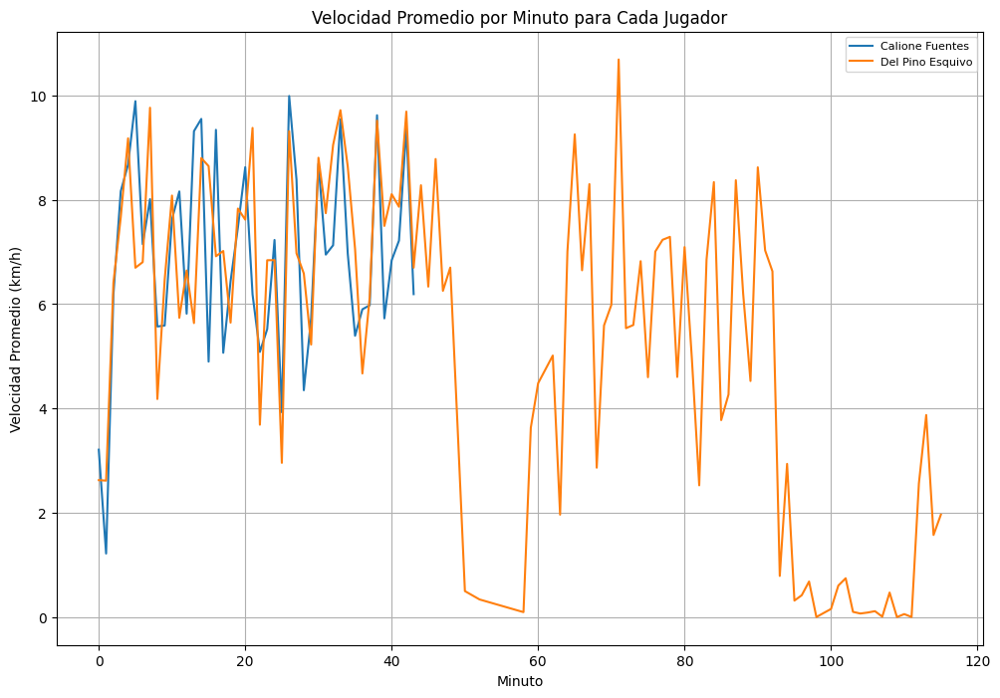

In [23]:
import matplotlib.pyplot as plt
import pandas as pd

# Asegúrate de que los datos están cargados en el DataFrame 'df'
df = df_backed_up.copy()

# Verificar el tipo de datos de 'Elapsed Time (s)'
print(f"Tipo de datos de 'Elapsed Time (s)': {df['Elapsed Time (s)'].dtype}")

# Si 'Elapsed Time (s)' está en formato Timestamp, convertirlo a segundos
if pd.api.types.is_datetime64_any_dtype(df['Elapsed Time (s)']):
    df['Elapsed Time (s)'] = (df['Elapsed Time (s)'] - df['Elapsed Time (s)'].min()).dt.total_seconds()

# Generar un tiempo relativo ficticio si los datos no están en el formato correcto
if df['Elapsed Time (s)'].max() <= 0:  # Verifica si los valores no tienen sentido
    print("Corrigiendo tiempos: Generando tiempos ficticios.")
    df['Elapsed Time (s)'] = df.index * 0.1  # Supone un incremento de 0.1 s entre filas

# Crear una nueva columna para agrupar por minuto
df['Minute'] = (df['Elapsed Time (s)'] // 60).astype(int)

# Verifica los valores en la columna 'Minute'
print("Primeros valores de la columna 'Minute':")
print(df[['Elapsed Time (s)', 'Minute']].head())

# Calcular la velocidad promedio por jugador y minuto
average_speeds = df.groupby(['Player Display Name', 'Minute'])['Speed km/h'].mean().reset_index()

# Crear el gráfico
plt.figure(figsize=(12, 8))

# Graficar la velocidad promedio de cada jugador por minuto
for player in average_speeds['Player Display Name'].unique():
    player_data = average_speeds[average_speeds['Player Display Name'] == player]
    plt.plot(player_data['Minute'], player_data['Speed km/h'], label=player)

# Añadir título y etiquetas
plt.title('Velocidad Promedio por Minuto para Cada Jugador')
plt.xlabel('Minuto')
plt.ylabel('Velocidad Promedio (km/h)')
plt.legend(loc='upper right', fontsize=8)
plt.grid(True)

# Mostrar el gráfico
plt.show()


El entretiempo detectado: 93 a 108 minutos.
El segundo tiempo comienza en el minuto: 109


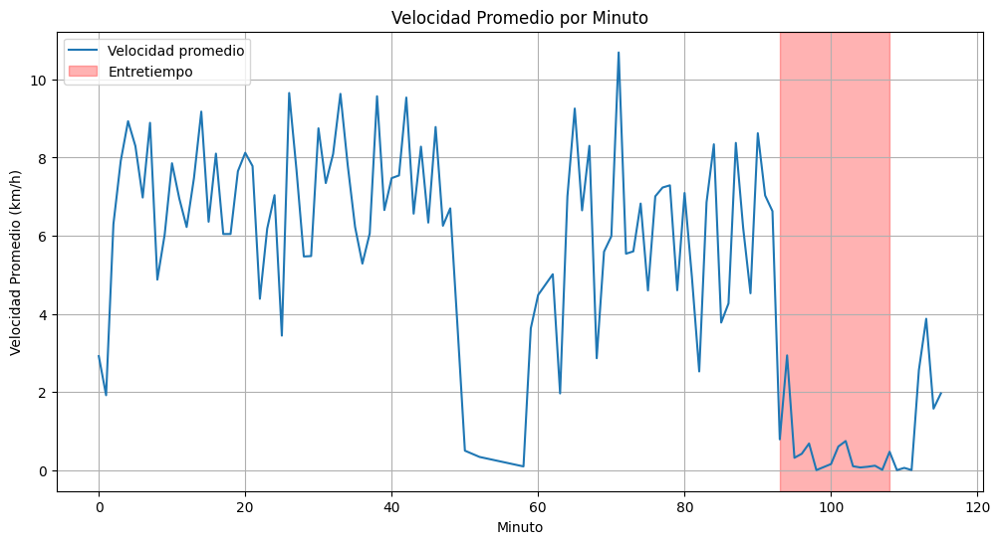

In [24]:
import numpy as np

VELOCIDAD_PARTIDO = 6

# Calcular la velocidad promedio por minuto
minute_avg_speed = df.groupby('Minute')['Speed km/h'].mean().reset_index()

# Identificar los minutos donde la velocidad promedio es <= 4.5 km/h
minute_avg_speed['IsHalftime'] = minute_avg_speed['Speed km/h'] <= VELOCIDAD_PARTIDO

# Detectar bloques consecutivos de entretiempo (al menos 10 minutos)
minute_avg_speed['Group'] = (minute_avg_speed['IsHalftime'] != minute_avg_speed['IsHalftime'].shift()).cumsum()

# Filtrar solo los bloques de entretiempo con al menos 10 minutos
halftime_blocks = minute_avg_speed[minute_avg_speed['IsHalftime']].groupby('Group').filter(lambda x: len(x) >= 10)

# Detectar el entretiempo con las restricciones dadas
if not halftime_blocks.empty:
    halftime_start = halftime_blocks['Minute'].min()  # Inicio del entretiempo preliminar
    halftime_end = halftime_blocks['Minute'].max()  # Final preliminar del entretiempo

    # Limitar el bloque de entretiempo a un máximo de 15 minutos
    max_halftime_end = halftime_start + 15
    halftime_end = min(halftime_end, max_halftime_end)

    # Refinar el final del entretiempo al detectar velocidades altas
    for minute in range(halftime_start, halftime_end + 1):
        current_speed = minute_avg_speed.loc[minute_avg_speed['Minute'] == minute, 'Speed km/h'].values[0]
        if current_speed > VELOCIDAD_PARTIDO:
            halftime_end = minute - 1
            break

    # El segundo tiempo comienza justo después del entretiempo
    second_half_start = halftime_end + 1
    print(f"El entretiempo detectado: {halftime_start} a {halftime_end} minutos.")
    print(f"El segundo tiempo comienza en el minuto: {second_half_start}")
else:
    print("No se pudo detectar un entretiempo claro.")

# Visualizar los promedios por minuto con el bloque de entretiempo marcado
plt.figure(figsize=(12, 6))
plt.plot(minute_avg_speed['Minute'], minute_avg_speed['Speed km/h'], label='Velocidad promedio')

# Sombrear el entretiempo
if not halftime_blocks.empty:
    plt.axvspan(halftime_start, halftime_end, color='red', alpha=0.3, label='Entretiempo')

# Añadir etiquetas y leyenda
plt.title('Velocidad Promedio por Minuto')
plt.xlabel('Minuto')
plt.ylabel('Velocidad Promedio (km/h)')
plt.legend()
plt.grid(True)
plt.show()


In [25]:
# Buscar el valor de Minute correspondiente al inicio del segundo tiempo
second_half_start_minute = second_half_start

# Filtrar el DataFrame para encontrar el primer registro de ese minuto
second_half_start_elapsed_time = df[df['Minute'] == second_half_start_minute]['Elapsed Time (s)'].min()
hora = df[df['Minute'] == second_half_start_minute]['Time'].min()

print(f"El segundo tiempo comienza en el Elapsed Time: {second_half_start_elapsed_time} segundos.")
print(f"Hora: {hora}")


El segundo tiempo comienza en el Elapsed Time: 6540.00646742061 segundos.
Hora: 10:52:56.00


No se pudo detectar un entretiempo claro.
6462
6240

Primer Tiempo:
  [Inicio] segundo: 108 minuto: 00:01:48 (hora: 09:05:44.00)
  [Fin] segundo: 2862 minuto: 00:47:42 (hora: 09:51:38.00)
  Duracion: 00:45:54 minutos

Segundo Tiempo:
  [Inicio] segundo: 3762 minuto: 01:02:42 (hora: 10:06:38.00)
  [Fin] segundo: 6462 minuto: 01:47:42 (hora: 10:51:38.00)
  Duracion: 00:45:00 minutos


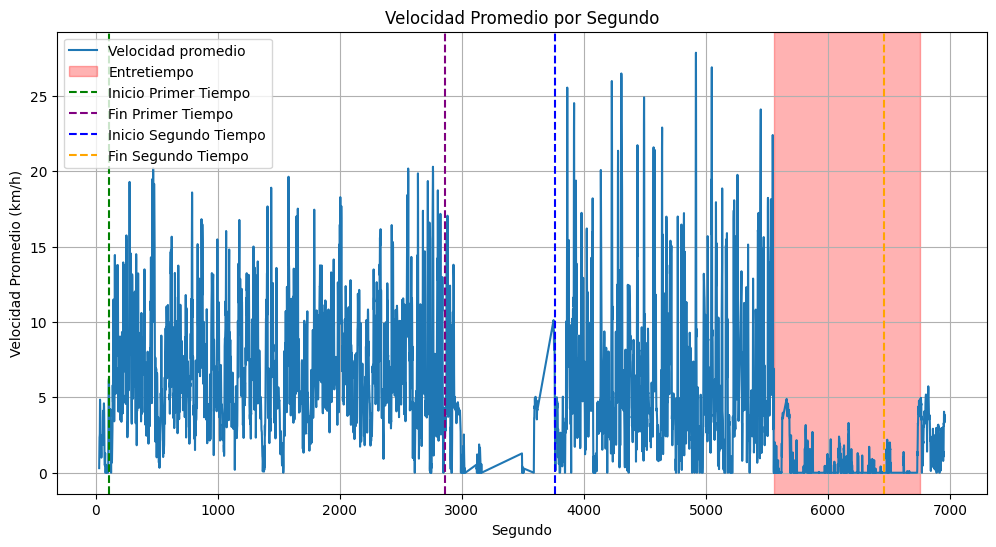

In [26]:
import numpy as np
import matplotlib.pyplot as plt


VENTANA_PRMER_TIEMPO = 20
VENTANA_SEGUNDO_TIEMPO = 10

# df = df_backed_up


# Calcular la velocidad promedio por cada segundo
df['Second'] = (df['Elapsed Time (s)'] // 1).astype(int)  # Asignar el segundo correspondiente para cada tiempo

# Agrupar por segundo y calcular la velocidad promedio
second_avg_speed = df.groupby('Second')['Speed km/h'].mean().reset_index()

# Filtrar el inicio del partido, descartando los primeros 30 segundos de inactividad
start_threshold = 30  # Ajustar este valor dependiendo del margen de inactividad antes del inicio
second_avg_speed = second_avg_speed[second_avg_speed['Second'] >= start_threshold]

# Identificar los segundos donde la velocidad promedio es <= 4.5 km/h (esto corresponde al entretiempo)
second_avg_speed['IsHalftime'] = second_avg_speed['Speed km/h'] <= VELOCIDAD_PARTIDO

# Detectar bloques consecutivos de entretiempo (al menos 15 minutos)
second_avg_speed['Group'] = (second_avg_speed['IsHalftime'] != second_avg_speed['IsHalftime'].shift()).cumsum()

# Filtrar solo los bloques de entretiempo con al menos 15 minutos
halftime_blocks = second_avg_speed[second_avg_speed['IsHalftime']].groupby('Group').filter(lambda x: len(x) >= 500)  # 15 minutos en segundos

# Detectar el entretiempo con las restricciones dadas
if not halftime_blocks.empty:
    try:
        halftime_start = halftime_blocks['Second'].min()  # Inicio del entretiempo
        halftime_end = halftime_blocks['Second'].max()  # Fin del entretiempo
    
        # Limitar el bloque de entretiempo a un máximo de 20 minutos (ajustable si es necesario)
        max_halftime_end = halftime_start + 1200  # 20 minutos en segundos
        halftime_end = min(halftime_end, max_halftime_end)
    
        # Refinar el final del entretiempo al detectar velocidades altas
        for second in range(halftime_start, halftime_end + 1):
            current_speed = second_avg_speed.loc[second_avg_speed['Second'] == second, 'Speed km/h'].values[0]
            if current_speed > VELOCIDAD_PARTIDO:
                halftime_end = second - 1
                break
    
        # El segundo tiempo comienza justo después del entretiempo
        second_half_start = halftime_end + 1
        print(f"El entretiempo detectado: {halftime_start} a {halftime_end} segundos.")
        print(f"El segundo tiempo comienza en el segundo: {second_half_start}")
    except:
        print("No se pudo detectar un entretiempo claro.")
else:
    print("No se pudo detectar un entretiempo claro.")

# Detectar el inicio del primer tiempo (el primer segundo con velocidad > 4.5 km/h)
first_half_start = second_avg_speed[second_avg_speed['Speed km/h'] > VELOCIDAD_PARTIDO].iloc[0]['Second']

# Asegurarse de que el primer tiempo dure al menos 45 minutos (2700 segundos)
first_half_end = first_half_start + 2700  # 45 minutos en segundos

# Ajustar el final del primer tiempo basado en cuando la velocidad promedio caiga por debajo de 4.5 km/h
window = 0
for second in range(first_half_end, len(second_avg_speed)):
    current_speed = second_avg_speed.loc[second_avg_speed['Second'] == second, 'Speed km/h'].values[0]
    if current_speed <= VELOCIDAD_PARTIDO:
        first_half_end = second - 1
        window += 1
        if window >= VENTANA_PRMER_TIEMPO:
            break
    else:
        window = 0


# Asegurarse de que el segundo tiempo dure al menos 45 minutos (2700 segundos)
second_half_start = max(first_half_end + 900, second_half_start)
second_half_end = second_half_start + 2700

print(second_half_end)
print(len(second_avg_speed))


# Ajustar el final del segundo tiempo basado en cuando la velocidad promedio caiga por debajo de 4.5 km/h
window = 0
for second in range(second_half_end, len(second_avg_speed)):
    current_speed = second_avg_speed.loc[second_avg_speed['Second'] == second, 'Speed km/h'].values[0]
    if current_speed <= VELOCIDAD_PARTIDO:
        # print(f"second: {second}, current: {current_speed}, window: {window}")
        second_half_end = second - 1
        window += 1
        if window >= VENTANA_SEGUNDO_TIEMPO:
            break
    else:
        window = 0

# Convertir segundos a formato de tiempo HH:MM:SS
def convert_seconds_to_time(seconds):
    return str(np.floor(seconds // 3600)).zfill(2) + ":" + str(np.floor((seconds % 3600) // 60)).zfill(2) + ":" + str(int(seconds % 60)).zfill(2)

# Imprimir los resultados con mayor precisión en segundos
print(f"\nPrimer Tiempo:")
print(f"  [Inicio] segundo: {first_half_start} minuto: {convert_seconds_to_time(first_half_start)} (hora: {df[df['Second'] == first_half_start]['Time'].iloc[0]})")
print(f"  [Fin] segundo: {first_half_end} minuto: {convert_seconds_to_time(first_half_end)} (hora: {df[df['Second'] == first_half_end]['Time'].iloc[0]})")
print(f"  Duracion: {convert_seconds_to_time(first_half_end-first_half_start)} minutos")

print(f"\nSegundo Tiempo:")
print(f"  [Inicio] segundo: {second_half_start} minuto: {convert_seconds_to_time(second_half_start)} (hora: {df[df['Second'] == second_half_start]['Time'].iloc[0]})")
print(f"  [Fin] segundo: {second_half_end} minuto: {convert_seconds_to_time(second_half_end)} (hora: {df[df['Second'] == second_half_end]['Time'].iloc[0]})")
print(f"  Duracion: {convert_seconds_to_time(second_half_end-second_half_start)} minutos")

# Visualizar los promedios por segundo con el bloque de entretiempo marcado
plt.figure(figsize=(12, 6))
plt.plot(second_avg_speed['Second'], second_avg_speed['Speed km/h'], label='Velocidad promedio')

# Sombrear el entretiempo
if not halftime_blocks.empty:
    plt.axvspan(halftime_start, halftime_end, color='red', alpha=0.3, label='Entretiempo')

# Añadir líneas para el inicio y fin de los tiempos
plt.axvline(first_half_start, color='green', linestyle='--', label='Inicio Primer Tiempo')
plt.axvline(first_half_end, color='purple', linestyle='--', label='Fin Primer Tiempo')
plt.axvline(second_half_start, color='blue', linestyle='--', label='Inicio Segundo Tiempo')
plt.axvline(second_half_end, color='orange', linestyle='--', label='Fin Segundo Tiempo')

# Añadir etiquetas y leyenda
plt.title('Velocidad Promedio por Segundo')
plt.xlabel('Segundo')
plt.ylabel('Velocidad Promedio (km/h)')
plt.legend()
plt.grid(True)
plt.show()


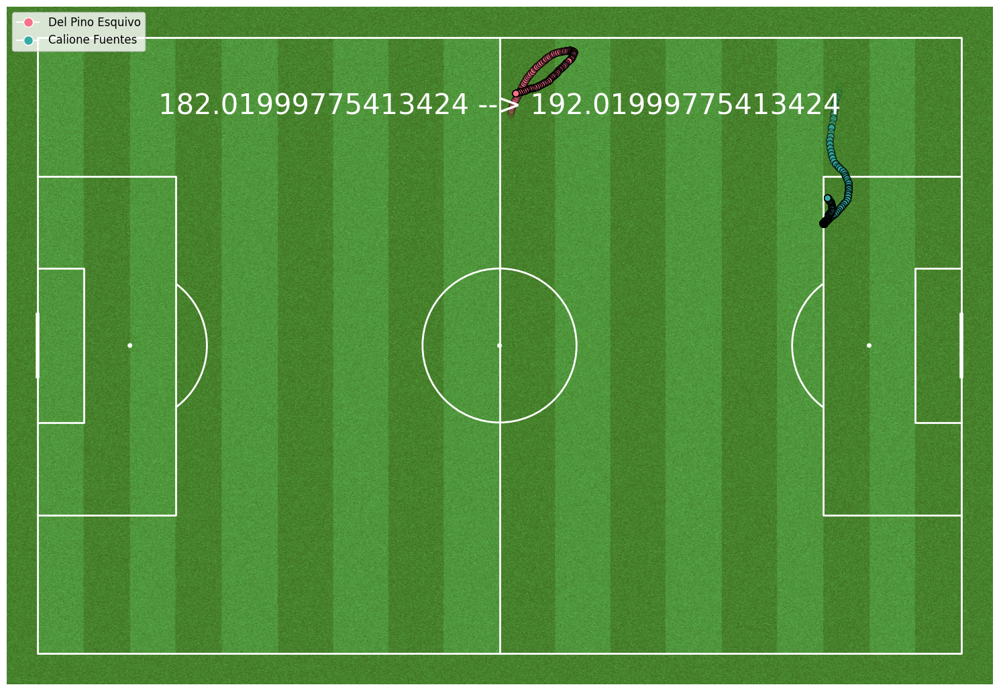

In [27]:
from matplotlib import pyplot as plt
import seaborn as sns
from mplsoccer import Pitch
from matplotlib.lines import Line2D


# Configuración inicial del campo
pitch = Pitch(pitch_color='grass', line_color='white', stripe=True)
fig, ax = pitch.draw(figsize=(16, 10.4))

# Configuración de la paleta de colores para los jugadores
paleta_colores = sns.color_palette("husl", n_colors=len(df['Player Display Name'].unique()))
colores = dict(zip(df['Player Display Name'].unique(), paleta_colores))

# comienzo_segundo_tiempo

# Filtrar datos para la ventana de tiempo
elapsed_time = min(df['Elapsed Time (s)'])
segundo = elapsed_time  + 182 #### OFICIALMENTE segundo 142
window = 10
df_window = df[(df['Elapsed Time (s)'] > segundo) & (df['Elapsed Time (s)'] < segundo + window)]

# Preparar el diccionario con los datos de cada jugador
player_data = {
    player: df_window[df_window['Player Display Name'] == player].reset_index(drop=True)
    for player in df_window['Player Display Name'].unique()
}

# Graficar los puntos de cada jugador
for player, data in player_data.items():
    # Obtener las coordenadas normalizadas de latitud y longitud
    lon_values = data['Lon_normalized']
    lat_values = data['Lat_normalized']
    
    # Calcular la opacidad con base en el índice de los datos (opacidad proporcional)
    opacidad = [i / len(data) for i in range(len(data))]
    
    # Graficar los puntos para el jugador con su color y opacidad
    ax.scatter(
        lon_values, lat_values, 
        color=colores[player], alpha=opacidad, 
        label=player, edgecolor='black', s=50, marker='o'
    )

# Crear leyenda personalizada con los colores de los jugadores
handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=colores[player], markersize=10, label=player)
           for player in df['Player Display Name'].unique()]

# Añadir la leyenda con los colores
ax.legend(handles=handles, loc='upper left', fontsize=12)

annotation = ax.annotate(f'{segundo} --> {segundo+window}', (60, 10), fontsize=30, ha='center', color="white")

# Mostrar el gráfico
plt.show()


## Segundo a segundo

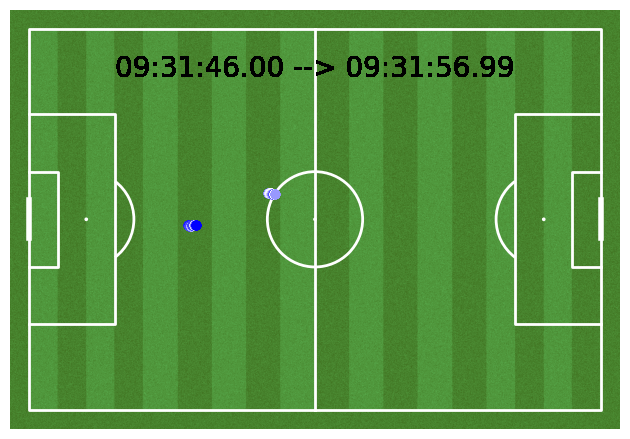

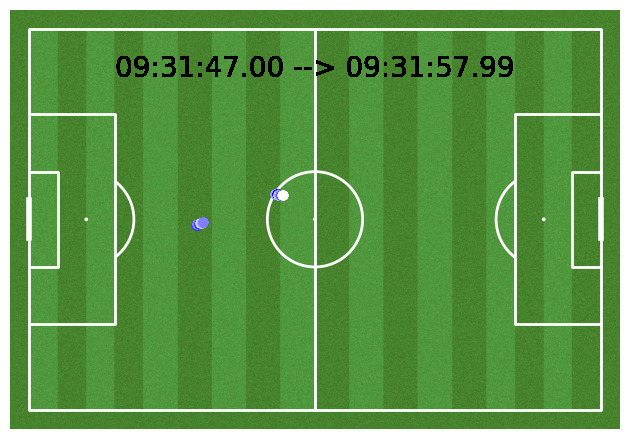

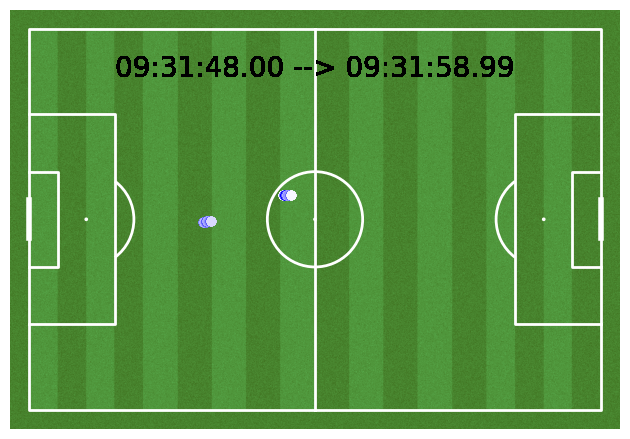

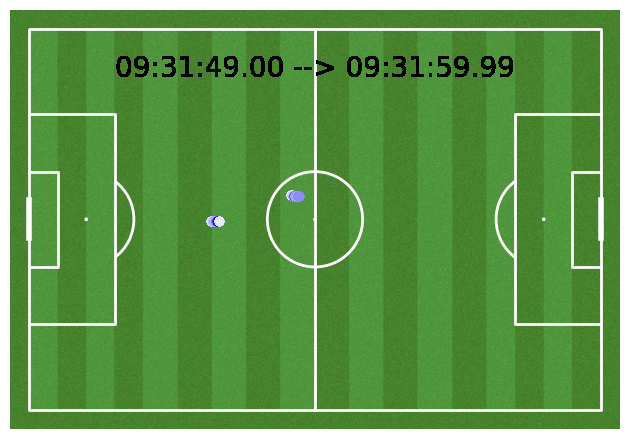

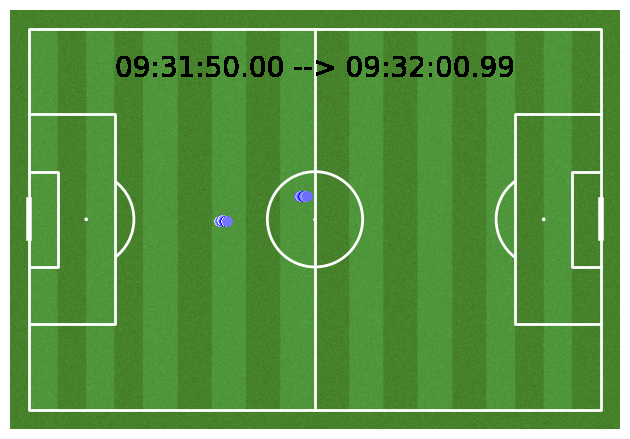

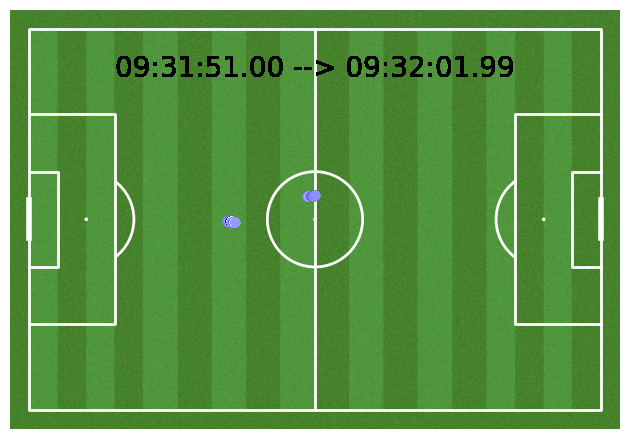

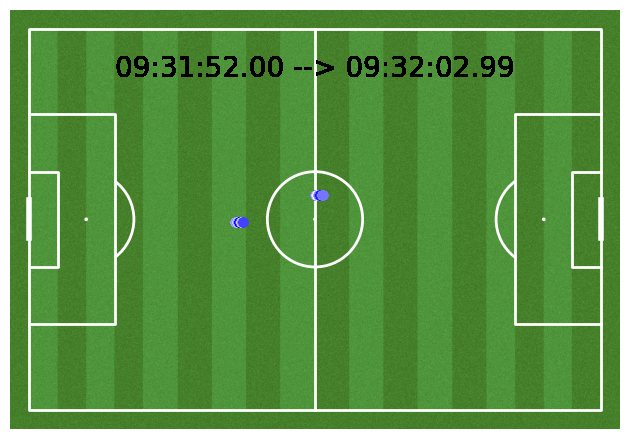

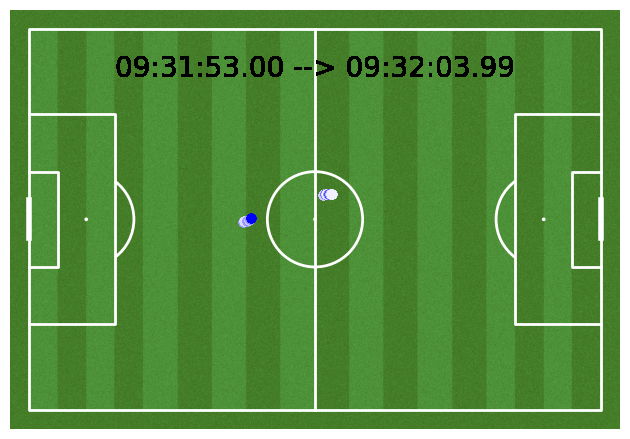

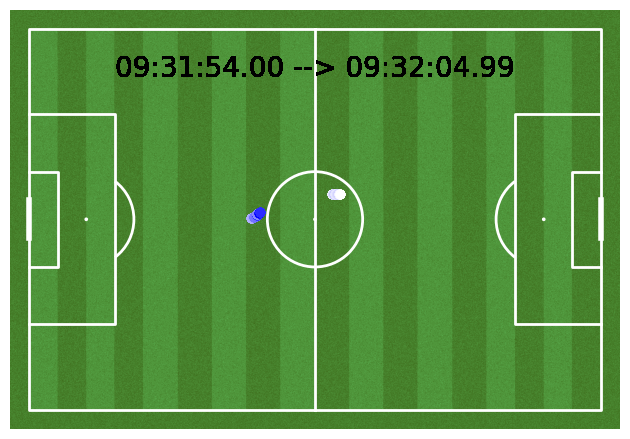

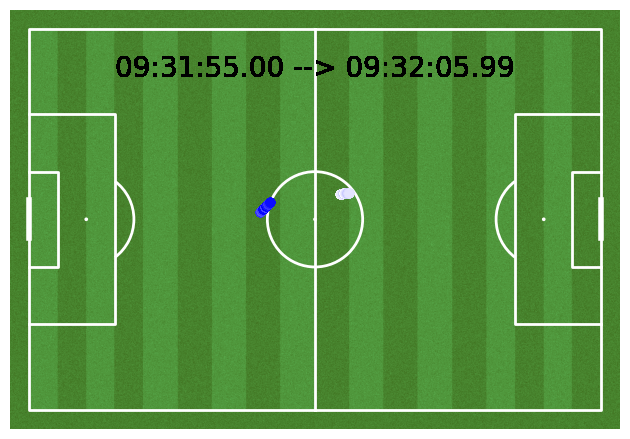

In [28]:
from mplsoccer import Pitch, VerticalPitch


# custom attempt

pitch = Pitch(pitch_color='grass', line_color='white',
              stripe=True)  # optional stripes
segundo = 1680

while segundo < 1690:

    fig, ax = pitch.draw()
    
    
    t0 = df[df['Elapsed Time (s)'] > segundo] 
    t0 = t0[t0['Elapsed Time (s)'] < segundo + 1]
    t0
    
    # print(len(t0))
    # print(t0)
    
    # cancha: 120x80
    
    step = 1
    colors = np.linspace(0, 1, len(t0))
    # Iterar avanzando de 10 en 10 elementos
    for i in range(0, len(t0), step):
        # color = (1, 1 - colors[i], 1 - colors[i])
        time_min = None
        time_max = None
        for index, row in t0.iloc[i:i+1].iterrows():
            # print(row['Lat_normalized'],row['Lon_normalized'])
            speed = row['Speed km/h']
            normalized_speed = (speed - t0['Speed km/h'].min()) / (t0['Speed km/h'].max() - t0['Speed km/h'].min())
            color = (1 - normalized_speed, 1 - normalized_speed, 1)  # Gradual transition from white to blue
            ax.scatter(row['Lon_normalized'], row['Lat_normalized'], c=color)
            if time_min is None:
                time_min = min(t0["Time"])
                time_max = max(t0["Time"])
            annotation = ax.annotate(f'{time_min} --> {time_max}', (60, 10), fontsize=20, ha='center')

    segundo+=1

In [29]:
speed_df = fix_df[fix_df['Speed km/h'] > 0.5]

In [30]:
def plot_velocidades_altas(v_min, subtitle=None ,use_df=None, v_max=None, color_param='R', step=1):
    pitch = Pitch(pitch_color='#aabb97', line_color='white',
              stripe_color='#c2d59d', stripe=True)  # optional stripes
    fig, ax = pitch.draw()
    if use_df is not None:
        fix_df = use_df 
    
    speed_df = fix_df[fix_df['Speed km/h'] > v_min]
    str = f'Velocidades > {v_min}km/h'
    
    if v_max:
        speed_df = speed_df[speed_df['Speed km/h'] < v_max]
        str = f'{str} y < {v_max}km/h'
    
    df = 
    
    print(subtitle, "Total de puntos: ", len(speed_df))
    annotation = ax.annotate(str, (60, 10), fontsize=20, ha='center', color="green")
    annotation_2 = ax.annotate(subtitle, (60, 20), fontsize=10, ha='center', color="green")
    
    # cancha: 120x80
    colors = np.linspace(0, 1, len(speed_df))
    # Iterar avanzando de 10 en 10 elementos
    for i in range(0, len(speed_df), step):
        # color = (1, 1 - colors[i], 1 - colors[i])
        for index, row in speed_df.iloc[i:i+1].iterrows():
            # print(row['Lat_normalized'],row['Lon_normalized'])
            speed = row['Speed km/h']
            normalized_speed = (speed - speed_df['Speed km/h'].min()) / (speed_df['Speed km/h'].max() - speed_df['Speed km/h'].min())
            if color_param == 'R':
                color = (1 - normalized_speed, 0, 0)  # Rojo
            elif color_param == 'G':
                color = (0, 1 - normalized_speed, 0)  # Verde
            elif color_param == 'B':
                color = (0, 0, 1 - normalized_speed)  # Azul
            else:
                color = (1, 1, 1)  # Blanco por defecto
            ax.scatter(row['Lon_normalized'], row['Lat_normalized'], c=color)

SyntaxError: invalid syntax (2151712012.py, line 15)

In [ ]:
# plot_velocidades_altas(25)

In [ ]:
# plot_velocidades_altas(20, v_max=25, color_param='B', step=2)

In [ ]:
# plot_velocidades_altas(15, v_max=20, color_param='G', step=3)

# Mapa de calor del partido

In [ ]:
import matplotlib.patheffects as path_effects

path_eff = [path_effects.Stroke(linewidth=1, foreground='black'),
            path_effects.Normal()]

pitch = Pitch(pitch_type='statsbomb', line_zorder=2, pitch_color='#f4edf0')
fig, ax = pitch.draw()
fig.set_facecolor('#f4edf0')

bin_statistic = pitch.bin_statistic(fix_df['Lon_normalized'], fix_df['Lat_normalized'], statistic='count', bins=(6, 5), normalize=True)
pitch.heatmap(bin_statistic, ax=ax, cmap='Reds', edgecolor='#f9f9f9')
labels = pitch.label_heatmap(bin_statistic, color='#f4edf0', fontsize=14,
                             ax=ax, ha='center', va='center',
                             str_format='{:.0%}', path_effects=path_eff)

# Analisis de Distancias

In [ ]:
import math

fix_df = fix_df[fix_df['Elapsed Time (s)'] > 0]

# Apply the rotation to the coordinates
fix_df['coord'] = list(zip(fix_df['Lat'], fix_df['Lon'], fix_df['Elapsed Time (s)']))
# Sample GPS coordinate data (latitude, longitude, timestamp)
gps_data = fix_df['coord']

# Function to calculate distance between two GPS coordinates
def calculate_distance(coord1, coord2):
    lat1, lon1, _ = coord1
    lat2, lon2, _ = coord2
    radius = 6371  # Earth's radius in kilometers
    lat1_rad = math.radians(lat1)
    lon1_rad = math.radians(lon1)
    lat2_rad = math.radians(lat2)
    lon2_rad = math.radians(lon2)
    delta_lat = lat2_rad - lat1_rad
    delta_lon = lon2_rad - lon1_rad
    a = math.sin(delta_lat / 2)**2 + math.cos(lat1_rad) * math.cos(lat2_rad) * math.sin(delta_lon / 2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    distance = radius * c
    return distance

# Threshold speed in km/h
threshold_speed = 20

# Variables to keep track of total distance and distance above threshold
total_distance = 0
distance_above_threshold = 0

for i in range(len(fix_df) - 1):
    coord1 = fix_df['coord'].iloc[i]
    coord2 = fix_df['coord'].iloc[i + 1]

    # Calculate the distance between two consecutive coordinates
    distance = calculate_distance(coord1, coord2)

    # Calculate the time elapsed between coordinates (in seconds)
    time_elapsed = 0.1 
    # time_elapsed ----> coord2[2] - coord1[2]
    # print(time_elapsed)

    # Calculate speed (distance / time) in km/h
    speed = (distance / time_elapsed) * 3600

    # Update total distance
    total_distance += distance

    # Check if speed is above the threshold
    if speed >= threshold_speed:
        distance_above_threshold += distance

print(f"Total distance run: {total_distance} km")
print(f"Distance above {threshold_speed} km/h: {distance_above_threshold} km")

In [ ]:
import matplotlib.pyplot as plt

# Distancia recorrida por debajo de threshold_speed km/h
distance_below_threshold = total_distance - distance_above_threshold

# Colores para los segmentos
colors = ['blue', 'orange']

# Etiquetas para los segmentos
labels = [f'< {threshold_speed} km/h', f'>= {threshold_speed} km/h']

# Alturas de los segmentos
heights = [distance_below_threshold, distance_above_threshold]

# Posiciones en el eje X para los segmentos
positions = [0, 0]

# Crear la figura y los ejes
fig, ax = plt.subplots()

# Dibujar el segmento de la barra
ax.bar(positions, heights, color=colors, tick_label=[total_distance])

# Configurar el eje y
ax.set_ylabel('Distancia (km)')

# Configurar el título
ax.set_title('Distancia Recorrida')

# Añadir una leyenda
ax.legend(labels)

# Mostrar la gráfica
plt.show()

# Umbral de Aceleraciones / Velocidades por jugador

In [ ]:
import pandas as pd


# Crear un DataFrame de ejemplo con coordenadas y velocidad
df = fix_df

# km/h => m/s
df['Speed m/s'] = list(df['Speed km/h']/3.6)
# df['Acceleration'] = list(df['Speed km/h']/3.6)

# Umbral de aceleración
threshold_acceleration = 4.9  # Ajusta el umbral según sea necesario


# Contador de veces que se supera el umbral de aceleración
count_exceeding_threshold = 0

rows_per_second = 10

when = []

# Iterar a través del DataFrame con saltos de 10 filas
for i in range(0, len(df) - rows_per_second, rows_per_second):
    # Obtener la velocidad actual y la velocidad anterior
    velocity_current = df['Speed m/s'].iloc[i]
    velocity_next = df['Speed m/s'].iloc[i + rows_per_second]

    # Calcular la aceleración como cambio en la velocidad dividido por el tiempo (1 segundo)
    acceleration = (velocity_next - velocity_current) / 1.0

    # Comparar la aceleración con el umbral
    if acceleration > threshold_acceleration:
        when.append([i])
        count_exceeding_threshold += 1

print(f"El umbral de aceleración se superó {count_exceeding_threshold} veces.")


In [ ]:
when

In [ ]:
def plot_aceleraciones_altas(a_max=3.5, subtitle=None, use_df=None, include_acc=False, color_param='R', step=1):
    
    # Crear un DataFrame de ejemplo con coordenadas y velocidad
    df = use_df
    
    # km/h => m/s
    df['Speed m/s'] = list(df['Speed km/h']/3.6)
    # df['Acceleration'] = list(df['Speed km/h']/3.6)
    
    # Umbral de aceleración
    threshold_acceleration = a_max  # Ajusta el umbral según sea necesario
    
    
    # Contador de veces que se supera el umbral de aceleración
    count_exceeding_threshold = 0
    
    rows_per_second = 10
    
    when = []
    
    # Iterar a través del DataFrame con saltos de 10 filas
    for i in range(0, len(df) - rows_per_second, rows_per_second):
        # Obtener la velocidad actual y la velocidad anterior
        velocity_current = df['Speed m/s'].iloc[i]
        velocity_next = df['Speed m/s'].iloc[i + rows_per_second]
    
        # Calcular la aceleración como cambio en la velocidad dividido por el tiempo (1 segundo)
        acceleration = (velocity_next - velocity_current) / 1.0
        # comment me for perfonmance
        if include_acc:
            df.at[i, 'Acceleration m/s^2'] = acceleration

        # Comparar la aceleración con el umbral
        if acceleration > threshold_acceleration:
            when.append([i])
            count_exceeding_threshold += 1
    
    print(f"El umbral de aceleración se superó {count_exceeding_threshold} veces.")
    
    filas_antes_despues = 10
    
    # DataFrame para almacenar las filas de interés
    df_resultado = pd.DataFrame()
    
    # Iterar a través de los índices de interés
    for indice in when:
        inicio = max(indice[0] - filas_antes_despues, 0)
        fin = min(indice[0] + filas_antes_despues + 1, len(df))
        filas_seleccionadas = df.iloc[inicio:fin]
        df_resultado = pd.concat([df_resultado, filas_seleccionadas])

    
    pitch = Pitch(pitch_color='grass', line_color='white',
                  stripe=True)  # optional stripes
    fig, ax = pitch.draw()

    df = df_resultado
    print(len(df))
    
    # cancha: 120x80
    
    step = 1
    colors = np.linspace(0, 1, len(df))
    # Iterar avanzando de 10 en 10 elementos
    for i in range(0, len(df), step):
        # color = (1, 1 - colors[i], 1 - colors[i])
        for index, row in df.iloc[i:i+1].iterrows():
            # print(row['Lat_normalized'],row['Lon_normalized'])
            speed = row['Speed km/h']
            normalized_speed = (speed - df['Speed km/h'].min()) / (df['Speed km/h'].max() - df['Speed km/h'].min())
            color = (1 - normalized_speed, 1 - normalized_speed, 1)  # Gradual transition from white to blue
            ax.scatter(row['Lon_normalized'], row['Lat_normalized'], c=color)
    
    
    plt.show()
    return df_resultado

In [ ]:
df = plot_aceleraciones_altas(a_max=4, use_df=df_backed_up)

In [ ]:
# plot_aceleraciones_altas(a_max=4, use_df=df, include_acc=True)

In [ ]:
df.head(100)

In [ ]:
grouped_df = df.groupby('Player Display Name').size()
grouped_df

In [ ]:
# grouped_df['Player Display Name']

In [ ]:
for name, group in df.groupby('Player Display Name'):
    # Filter the group based on 'Player Display Name'
    filtered_group = df[df['Player Display Name'] == name]
    plot_velocidades_altas(25, subtitle=name, use_df=filtered_group)
    plot_aceleraciones_altas(use_df=filtered_group)

In [ ]:
for name, group in df.groupby('Player Display Name'):
    # Filter the group based on 'Player Display Name'
    filtered_group = df[df['Player Display Name'] == name]
    plot_velocidades_altas(30, subtitle=name, use_df=filtered_group)